# 03 — When Your Sample Is Biased

The first two notebooks were about drawing numbers correctly. This one is about the more
common and more expensive failure: the draw is correct and the *answer* is still wrong.

**The question this notebook answers:** random with respect to *what*?

A simple random sample is unbiased. That is a real guarantee and it is not enough, for two
separate reasons. First, unbiased does not mean precise — an estimator can be centred on
the truth and still swing wildly from sample to sample. Second, the guarantee only holds
for the population you actually sampled from, which is often not the population you meant.

We build a population with a known mean, so every estimate can be scored against the exact
answer rather than against another estimate.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from src.config import load_settings, make_rng
from src.datasets.populations import (
    grouped_population,
    response_propensity,
    skewed_population,
)
from src.reporting import save_results
from src.survey.bias import (
    convenience_frame_mean,
    frame_limit_mean,
    response_biased_mean,
)
from src.survey.grouped import (
    cluster_mean,
    group_leakage_rate,
    group_train_test_split,
    naive_row_split,
)
from src.survey.simple import simple_random_mean
from src.survey.stratified import (
    neyman_allocation,
    proportional_allocation,
    stratified_mean,
)
from src.visualisation import (
    plot_bias_comparison,
    plot_estimate_spread,
    plot_leakage,
    plot_population_skew,
    save_figure,
)

settings = load_settings()
cfg = settings.survey
rng = make_rng()

N_SIMS = settings.n_simulations
N = cfg.sample_size

population = skewed_population(
    cfg.population_size, cfg.strata_proportions, cfg.strata_means, cfg.strata_sds, rng
)
TRUTH = population.true_mean

print(f"seed = {settings.seed}")
print(f"population = {population.size:,} units, sample size = {N:,}, "
      f"{N_SIMS} repeated samples")
print(f"\nTRUE population mean = {TRUTH:.4f}   (known exactly: the population is enumerated)")

seed = 20260909
population = 100,000 units, sample size = 1,000, 300 repeated samples

TRUE population mean = 52.6832   (known exactly: the population is enumerated)


## The population

Four strata of very different size and spread. Think customer spend, insurance claims,
city populations — anything where a small group carries a large share of the total.

stratum 0: 70,000 units (70.0%)  mean   29.97  sd    7.99  holds 39.8% of the total
stratum 1: 20,000 units (20.0%)  mean   60.07  sd   14.91  holds 22.8% of the total
stratum 2:  8,000 units ( 8.0%)  mean  119.78  sd   41.12  holds 18.2% of the total
stratum 3:  2,000 units ( 2.0%)  mean  505.47  sd  201.24  holds 19.2% of the total


/workspaces/sampling_101/outputs/figures/03_population_skew.png


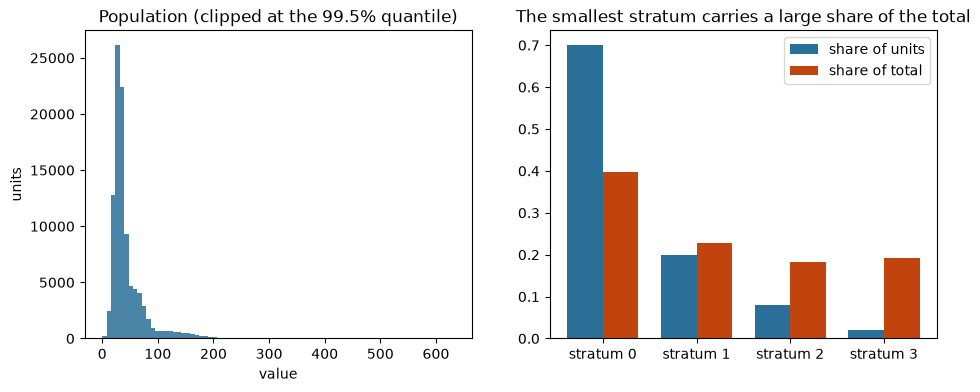

In [2]:
sizes = population.stratum_sizes()
for h, size in enumerate(sizes):
    values = population.values[population.strata == h]
    print(f"stratum {h}: {size:6,} units ({size / population.size:5.1%})  "
          f"mean {values.mean():7.2f}  sd {values.std():7.2f}  "
          f"holds {values.sum() / population.values.sum():5.1%} of the total")

fig = plot_population_skew(population.values, population.strata)
print(save_figure(fig, "03_population_skew"))

Stratum 3 is 2% of the units and carries around 19% of the total. Whether a sample happens
to catch a representative number of those units is the dominant source of error — and
simple random sampling leaves it entirely to chance.

## Design 1: simple random sampling

Unbiased, and that is the problem: being right *on average* says nothing about being
right *this time*. We draw the same sample 300 times and look at the spread.

In [3]:
srs = np.array([simple_random_mean(population.values, N, rng).value for _ in range(N_SIMS)])

print(f"mean of {N_SIMS} estimates : {srs.mean():.4f}   (truth {TRUTH:.4f})")
print(f"standard deviation        : {srs.std(ddof=1):.4f}")
print(f"worst estimate            : {srs.min():.4f} to {srs.max():.4f}")
print(f"\nUnbiased, yes. But an individual sample can be off by "
      f"{max(abs(srs.max() - TRUTH), abs(srs.min() - TRUTH)):.2f}.")

mean of 300 estimates : 52.5001   (truth 52.6832)
standard deviation        : 2.5284
worst estimate            : 46.4317 to 60.2742

Unbiased, yes. But an individual sample can be off by 7.59.


## Design 2: stratified sampling

Split the population into the strata, then sample *within* each one. The lottery over how
many rare-stratum units you caught disappears, because that number is now fixed by design.

The estimator is the stratum-size-weighted average of the within-stratum means. Only
variation *within* strata enters its variance; variation *between* strata does not.

In [4]:
counts = sizes
alloc_prop = proportional_allocation(counts, N)
sds = np.array([population.values[population.strata == h].std(ddof=1) for h in range(4)])
alloc_neyman = neyman_allocation(counts, sds, N)

print("stratum   units    proportional   Neyman")
for h in range(4):
    print(f"   {h}     {counts[h]:6,}        {alloc_prop[h]:5}      {alloc_neyman[h]:5}")
print(f"\nProportional allocation mirrors the population. Neyman allocation spends the")
print(f"sample where the variance is, which is the small, wildly spread stratum 3.")

stratum   units    proportional   Neyman
   0     70,000          700        352
   1     20,000          200        188
   2      8,000           80        207
   3      2,000           20        253

Proportional allocation mirrors the population. Neyman allocation spends the
sample where the variance is, which is the small, wildly spread stratum 3.


design                 mean       sd      variance vs simple random
simple random       52.5001   2.5284      1.00x
stratified (prop)   52.6164   0.9658      0.15x  (6.9x better)
stratified (Neyman) 52.6844   0.4765      0.04x  (28.2x better)

truth = 52.6832. All three are unbiased; they differ only in precision.


/workspaces/sampling_101/outputs/figures/03_estimate_spread.png


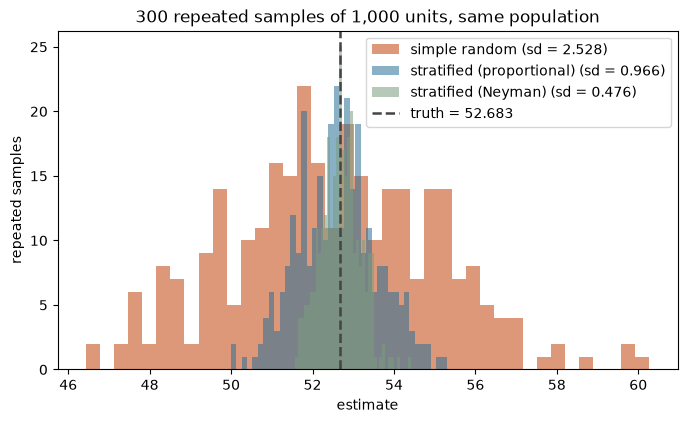

In [5]:
stratified = np.array(
    [stratified_mean(population.values, population.strata, N, rng).value for _ in range(N_SIMS)]
)
neyman = np.array(
    [
        stratified_mean(population.values, population.strata, N, rng, allocation="neyman").value
        for _ in range(N_SIMS)
    ]
)

variance_ratio_prop = srs.var(ddof=1) / stratified.var(ddof=1)
variance_ratio_neyman = srs.var(ddof=1) / neyman.var(ddof=1)

print(f"design                 mean       sd      variance vs simple random")
print(f"simple random      {srs.mean():8.4f}  {srs.std(ddof=1):7.4f}      1.00x")
print(f"stratified (prop)  {stratified.mean():8.4f}  {stratified.std(ddof=1):7.4f}    "
      f"  {1 / variance_ratio_prop:.2f}x  ({variance_ratio_prop:.1f}x better)")
print(f"stratified (Neyman){neyman.mean():8.4f}  {neyman.std(ddof=1):7.4f}    "
      f"  {1 / variance_ratio_neyman:.2f}x  ({variance_ratio_neyman:.1f}x better)")
print(f"\ntruth = {TRUTH:.4f}. All three are unbiased; they differ only in precision.")

fig = plot_estimate_spread(
    {"simple random": srs, "stratified (proportional)": stratified, "stratified (Neyman)": neyman},
    TRUTH,
    f"{N_SIMS} repeated samples of {N:,} units, same population",
)
print(save_figure(fig, "03_estimate_spread"))

All three histograms sit on the truth. One is far narrower than the others. Stratifying
bought a variance reduction *for free* — same sample size, same cost, better answer.

The reason is worth stating plainly: **stratification does not remove bias, it removes
variance.** It is not a fix for a broken sample; it is a way to spend the same sample
more intelligently.

## Now the failures that stratifying cannot fix

Both designs above sampled the whole population correctly. The next two do not, and no
amount of sample size will save them.

### Selection bias: the people who answer are not the people you asked

A survey where the probability of responding rises with the value being measured. The
draw itself is flawless. The frame is the problem.

In [6]:
propensity = response_propensity(population.values, cfg.response_strength)
response_bias = response_biased_mean(population.values, propensity, N, rng)

top_share_units = float((population.strata == 3).mean())
top_share_frame = float(propensity[population.strata == 3].sum())

print(f"The tilt is mild: the top stratum is {top_share_units:.1%} of units but")
print(f"{top_share_frame:.1%} of the response frame. High-value units are roughly twice as")
print(f"likely to answer, which is an unremarkable thing to be true of a real survey.\n")
print(f"truth                    {response_bias.truth:.4f}")
print(f"estimate from responders {response_bias.estimate:.4f}")
print(f"bias                     {response_bias.bias:+.4f}  "
      f"({response_bias.relative_bias:+.1%})")

The tilt is mild: the top stratum is 2.0% of units but
4.2% of the response frame. High-value units are roughly twice as
likely to answer, which is an unremarkable thing to be true of a real survey.

truth                    52.6832
estimate from responders 62.0270
bias                     +9.3438  (+17.7%)


### Does more data help?

This is the test that separates bias from noise. Take 100 times as many responses.

In [7]:
# The biased estimator has a computable limit: the mean under the sampling distribution
# it actually uses, sum_i p_i * x_i. More data converges to THIS, not to the truth.
frame_limit = frame_limit_mean(population.values, propensity)

print(f"responses    estimate    error vs truth    error vs frame limit")
for n_resp in (500, 5_000, 50_000, 500_000):
    est = response_biased_mean(population.values, propensity, n_resp, rng)
    print(f"{n_resp:>9,}    {est.estimate:8.4f}    {est.estimate - TRUTH:+13.4f}    "
          f"{est.estimate - frame_limit:+19.4f}")

print(f"\ntruth        = {TRUTH:.4f}")
print(f"frame limit  = {frame_limit:.4f}   <- what more data converges to")
print(f"\nThe error against the truth does not shrink. The error against the frame limit")
print(f"does. More data estimates the wrong quantity ever more precisely.")

small = response_biased_mean(population.values, propensity, 500, rng)
large = response_biased_mean(population.values, propensity, 50_000, rng)

responses    estimate    error vs truth    error vs frame limit
      500     63.1291         +10.4460                -2.9658


    5,000     66.0989         +13.4157                +0.0040
   50,000     66.7971         +14.1139                +0.7021
  500,000     66.0129         +13.3297                -0.0821

truth        = 52.6832
frame limit  = 66.0949   <- what more data converges to

The error against the truth does not shrink. The error against the frame limit
does. More data estimates the wrong quantity ever more precisely.


### A convenient frame

Here the sampling is textbook-correct simple random sampling — but of a frame that
happens to exclude the high-value stratum. Online panel, business hours, one region.

frame covers 98.0% of units but only 80.8% of the total

truth              52.6832
estimate           42.8687
bias               -9.8145  (-18.6%)
/workspaces/sampling_101/outputs/figures/03_selection_bias.png


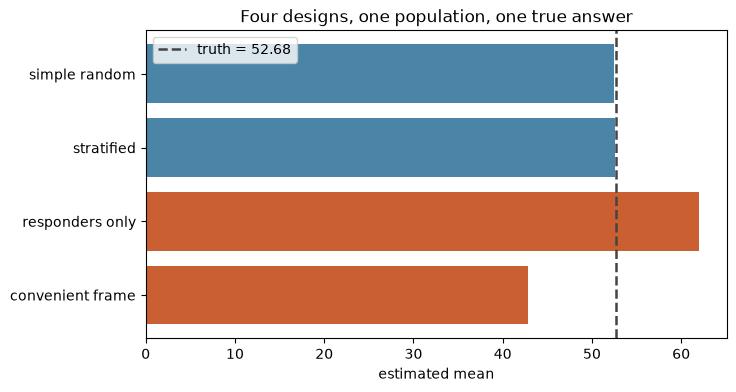

In [8]:
in_frame = population.strata < 3
frame_bias = convenience_frame_mean(population.values, in_frame, N, rng)

print(f"frame covers {in_frame.mean():.1%} of units but only "
      f"{population.values[in_frame].sum() / population.values.sum():.1%} of the total")
print(f"\ntruth              {frame_bias.truth:.4f}")
print(f"estimate           {frame_bias.estimate:.4f}")
print(f"bias               {frame_bias.bias:+.4f}  ({frame_bias.relative_bias:+.1%})")

fig = plot_bias_comparison(
    ["simple random", "stratified", "responders only", "convenient frame"],
    [srs.mean(), stratified.mean(), response_bias.estimate, frame_bias.estimate],
    TRUTH,
    "Four designs, one population, one true answer",
)
print(save_figure(fig, "03_selection_bias"))

## The grouped-data trap

The last failure is the one that shows up most often in machine learning. When rows nest
inside entities — customers, patients, sessions, devices — the rows are not independent.

Splitting *rows* at random puts the same entity on both sides of the split. The model
then sees a near-duplicate of each test row during training, and the test score measures
memorisation rather than generalisation.

10,000 rows nested in 400 entities (25 rows each)

random row split : 100.0% of test entities also appear in training
group-aware split: 0.0%
/workspaces/sampling_101/outputs/figures/03_group_leakage.png


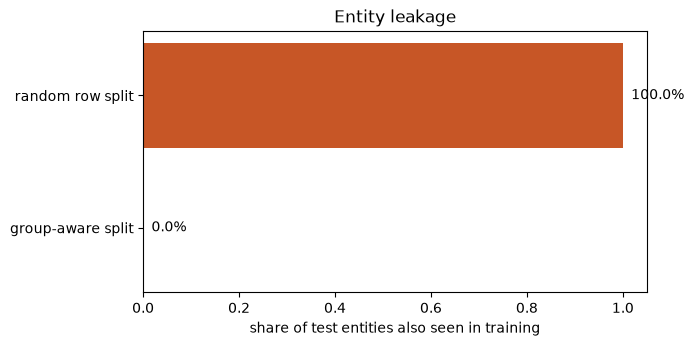

In [9]:
grouped = grouped_population(
    cfg.n_groups, cfg.group_size, rng, cfg.between_group_sd, cfg.within_group_sd
)

naive_train, naive_test = naive_row_split(grouped.size, 0.25, rng)
group_train, group_test = group_train_test_split(grouped.groups, 0.25, rng)

naive_leak = group_leakage_rate(grouped.groups, naive_train, naive_test)
group_leak = group_leakage_rate(grouped.groups, group_train, group_test)

print(f"{grouped.size:,} rows nested in {grouped.n_groups} entities "
      f"({cfg.group_size} rows each)")
print(f"\nrandom row split : {naive_leak:.1%} of test entities also appear in training")
print(f"group-aware split: {group_leak:.1%}")

fig = plot_leakage(naive_leak, group_leak)
print(save_figure(fig, "03_group_leakage"))

### Grouping cuts the other way too

The same structure that makes stratification *helpful* makes cluster sampling *harmful*.
Sampling whole entities is cheap, but rows within an entity repeat information, so the
effective sample size is the number of entities, not the number of rows.

In [10]:
n_clusters = 40
n_rows_equivalent = n_clusters * cfg.group_size

cluster = cluster_mean(grouped.values, grouped.groups, n_clusters, rng)
simple = simple_random_mean(grouped.values, n_rows_equivalent, rng)

print(f"cluster sample : {n_clusters} entities = {n_rows_equivalent:,} rows, "
      f"se = {cluster.se:.4f}")
print(f"simple random  : {n_rows_equivalent:,} rows,                se = {simple.se:.4f}")
print(f"\nSame number of rows, {cluster.se / simple.se:.1f}x the standard error. The extra")
print(f"rows inside each entity are close to free duplicates.")

cluster sample : 40 entities = 1,000 rows, se = 1.5283
simple random  : 1,000 rows,                se = 0.3881

Same number of rows, 3.9x the standard error. The extra
rows inside each entity are close to free duplicates.


## Saving the results

In [11]:
results = {
    "notebook": "03_when_your_sample_is_biased",
    "seed": settings.seed,
    "population_size": population.size,
    "sample_size": N,
    "n_simulations": N_SIMS,
    "true_mean": TRUTH,
    "strata": [
        {
            "stratum": h,
            "units": int(sizes[h]),
            "share_of_units": float(sizes[h] / population.size),
            "share_of_total": float(
                population.values[population.strata == h].sum() / population.values.sum()
            ),
            "mean": float(population.values[population.strata == h].mean()),
            "sd": float(population.values[population.strata == h].std()),
            "allocation_proportional": int(alloc_prop[h]),
            "allocation_neyman": int(alloc_neyman[h]),
        }
        for h in range(4)
    ],
    "designs": {
        "simple_random": {"mean": float(srs.mean()), "sd": float(srs.std(ddof=1))},
        "stratified_proportional": {
            "mean": float(stratified.mean()),
            "sd": float(stratified.std(ddof=1)),
            "variance_reduction_vs_simple": float(variance_ratio_prop),
        },
        "stratified_neyman": {
            "mean": float(neyman.mean()),
            "sd": float(neyman.std(ddof=1)),
            "variance_reduction_vs_simple": float(variance_ratio_neyman),
        },
    },
    "selection_bias": {
        "response_bias": {
            "truth": response_bias.truth,
            "estimate": response_bias.estimate,
            "bias": response_bias.bias,
            "relative_bias": response_bias.relative_bias,
            "response_strength": cfg.response_strength,
            "top_stratum_share_of_units": top_share_units,
            "top_stratum_share_of_frame": top_share_frame,
        },
        "more_data_does_not_help": {
            "bias_at_500": small.bias,
            "bias_at_50000": large.bias,
            "frame_limit": frame_limit,
            "frame_limit_bias": frame_limit - TRUTH,
        },
        "convenience_frame": {
            "truth": frame_bias.truth,
            "estimate": frame_bias.estimate,
            "bias": frame_bias.bias,
            "relative_bias": frame_bias.relative_bias,
            "frame_share_of_units": float(in_frame.mean()),
        },
    },
    "grouped_data": {
        "n_rows": grouped.size,
        "n_entities": grouped.n_groups,
        "leakage_random_row_split": naive_leak,
        "leakage_group_aware_split": group_leak,
        "cluster_se": cluster.se,
        "simple_random_se_same_rows": simple.se,
        "se_ratio": float(cluster.se / simple.se),
    },
    "findings": [
        f"Stratified sampling cut the estimator variance {variance_ratio_prop:.1f}x "
        f"versus simple random, at identical sample size.",
        f"Neyman allocation cut it {variance_ratio_neyman:.1f}x.",
        "Stratification removes variance, not bias.",
        f"Response bias shifted the estimate {response_bias.relative_bias:+.1%} and "
        f"100x more data did not reduce it.",
        f"A random row split leaked {naive_leak:.0%} of test entities into training; "
        f"a group-aware split leaked none.",
    ],
    "figures": [
        "03_population_skew",
        "03_estimate_spread",
        "03_selection_bias",
        "03_group_leakage",
    ],
}
print(save_results("03_when_your_sample_is_biased", results))

/workspaces/sampling_101/outputs/results/03_when_your_sample_is_biased.json


## What this bought you

The rule is one question: **random with respect to what?**

- **Stratify** on the variable that drives the outcome. Same cost, less variance, and
  rare classes cannot be missed. Use it for train-test splits too.
- **Group by entity** whenever rows nest inside something. A random row split leaked
  essentially every test entity into training here.
- **Interrogate the frame.** Who could not have been sampled? Selection bias is invisible
  in the sample — it looks completely healthy — and more data makes it worse by
  tightening the interval around a wrong answer.
- **Unbiased is not enough.** Simple random sampling was unbiased in every experiment
  above and still the worst design on offer.

Next: [04 — Monte Carlo](04_monte_carlo.ipynb), where sampling stops being how we measure
a population and becomes how we compute things that have no formula.